In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url=r"C:\Users\bisha\Downloads\AirPassengers.csv"
df=pd.read_csv(url,index_col='Month',parse_dates=['Month'])

In [3]:
df.head()

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


## Visualisation of Problem

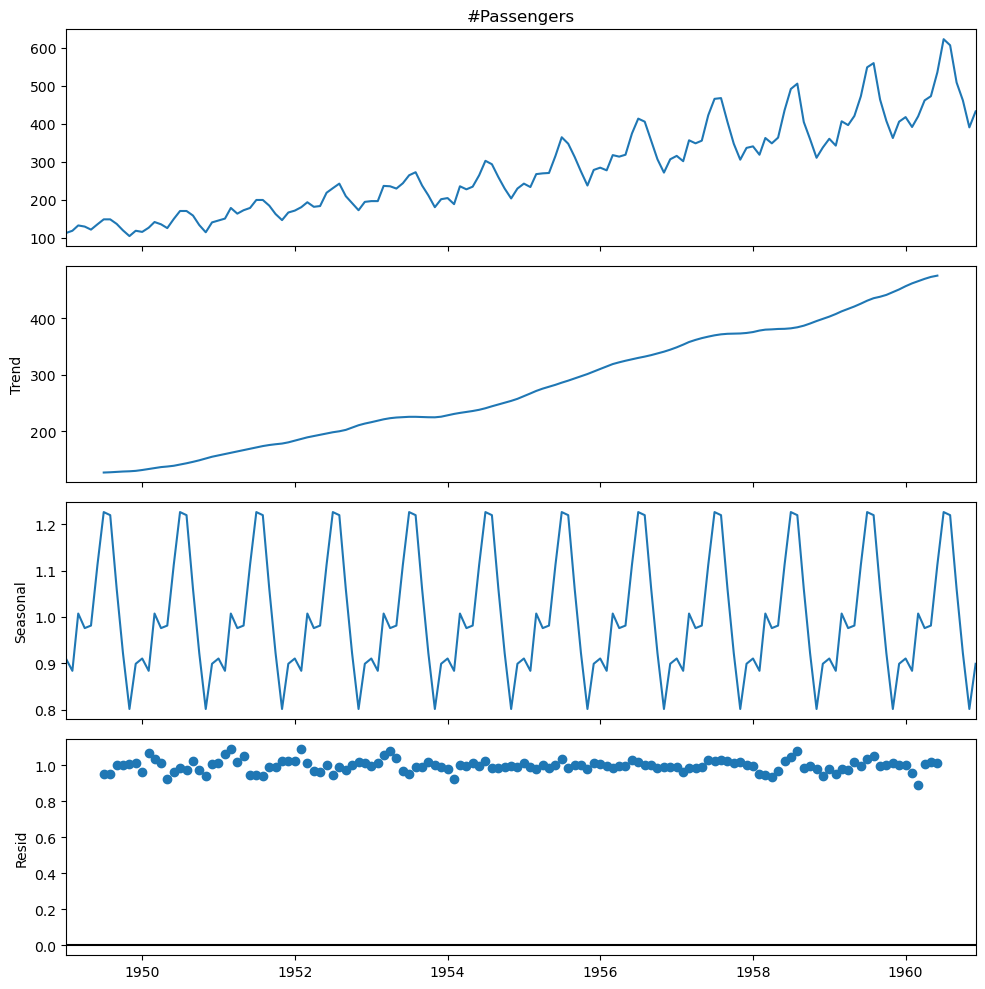

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

result=seasonal_decompose(df['#Passengers'],model='multiplicative')
plt.rcParams.update({'figure.figsize':(10,10)})
result.plot()
plt.show()

## Checking of stationarity

In [5]:
from statsmodels.tsa.stattools import adfuller
def time_stationarity(timeseries):
    rolmean=pd.Series(timeseries).rolling(window=12).mean()
    rolstd=pd.Series(timeseries).rolling(window=12).std()

    plt.figure(figsize=(10,10))
    orig=plt.plot(timeseries,color='blue',label='Original')
    mean=plt.plot(rolmean,color='red',label='Rolling Mean')
    std=plt.plot(rolstd,color='black',label='Rolling Std')
    plt.legend(loc='best')
    plt.title('graphs')
    plt.show(block=False)

    dftest=adfuller(timeseries,autolag='AIC')
    print('P value',dftest[1])
    print('critical values',dftest[4])
    print('ADF statistic',dftest[0])

In [6]:
x_train=df.iloc[:-12]
x_test=df.iloc[-12:]


In [7]:
ts=x_train['#Passengers']
ts

Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
             ... 
1959-08-01    559
1959-09-01    463
1959-10-01    407
1959-11-01    362
1959-12-01    405
Name: #Passengers, Length: 132, dtype: int64

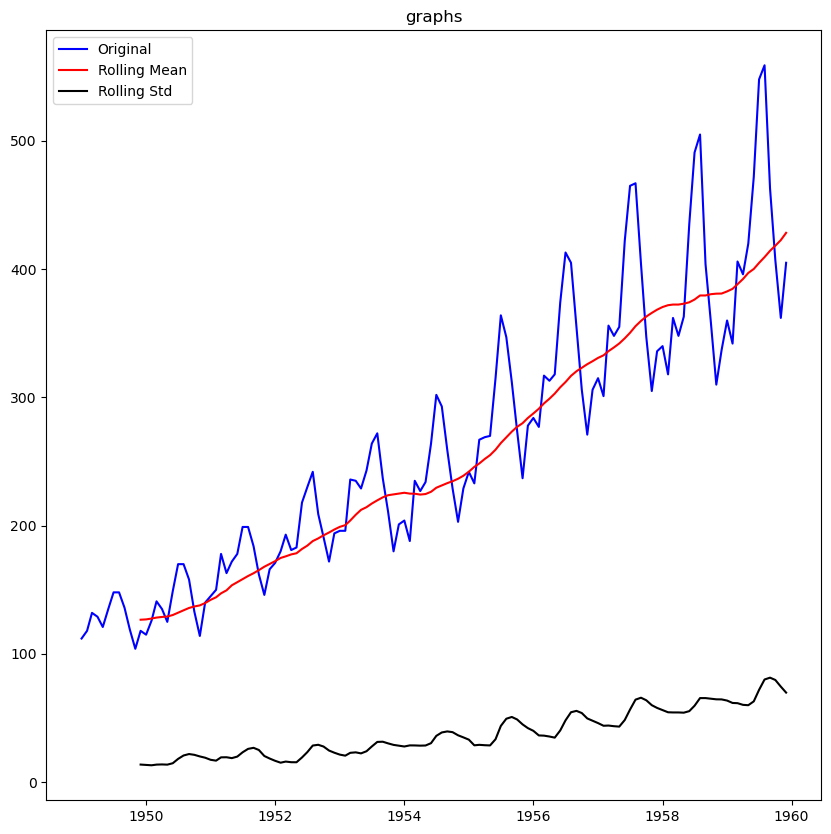

P value 0.9929320626482829
critical values {'1%': -3.4870216863700767, '5%': -2.8863625166643136, '10%': -2.580009026141913}
ADF statistic 0.8880265130074997


In [8]:
time_stationarity(ts)

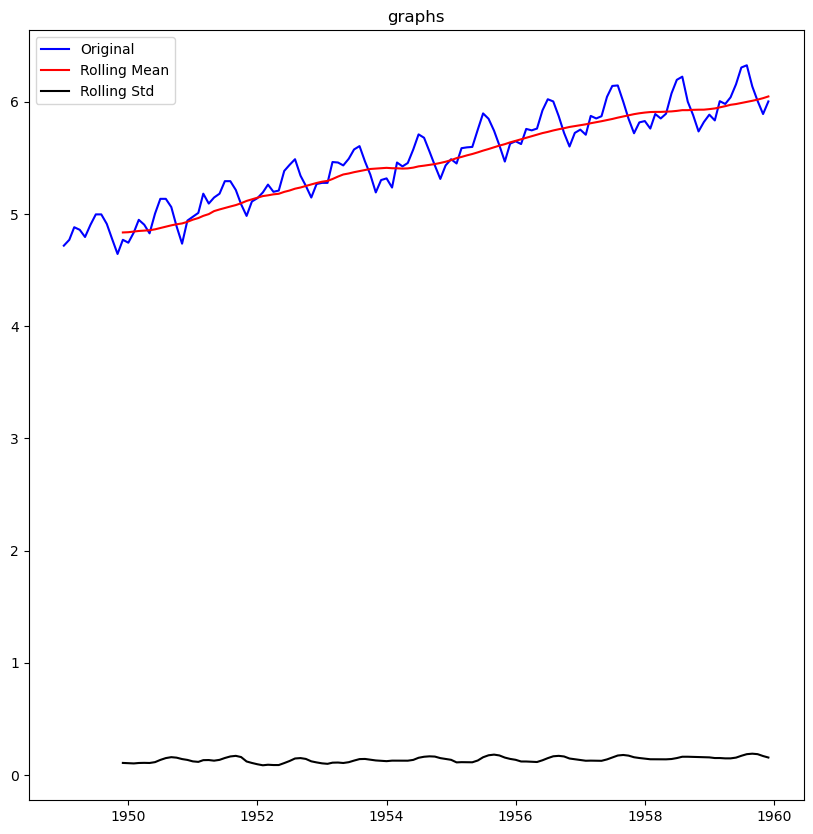

P value 0.6210771494355888
critical values {'1%': -3.4870216863700767, '5%': -2.8863625166643136, '10%': -2.580009026141913}
ADF statistic -1.3176112021439934


In [9]:
ts_log=np.log(ts)
time_stationarity(ts_log)

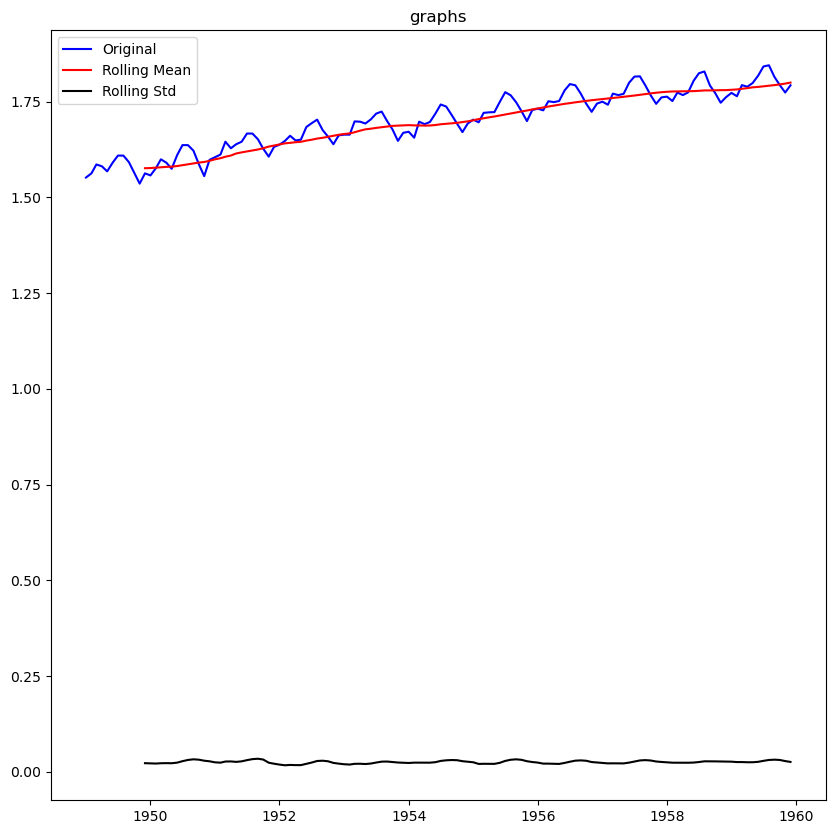

P value 0.4055646997835193
critical values {'1%': -3.4870216863700767, '5%': -2.8863625166643136, '10%': -2.580009026141913}
ADF statistic -1.7499755961422836


In [10]:
ts_dlog=np.log(ts_log)
time_stationarity(ts_dlog)

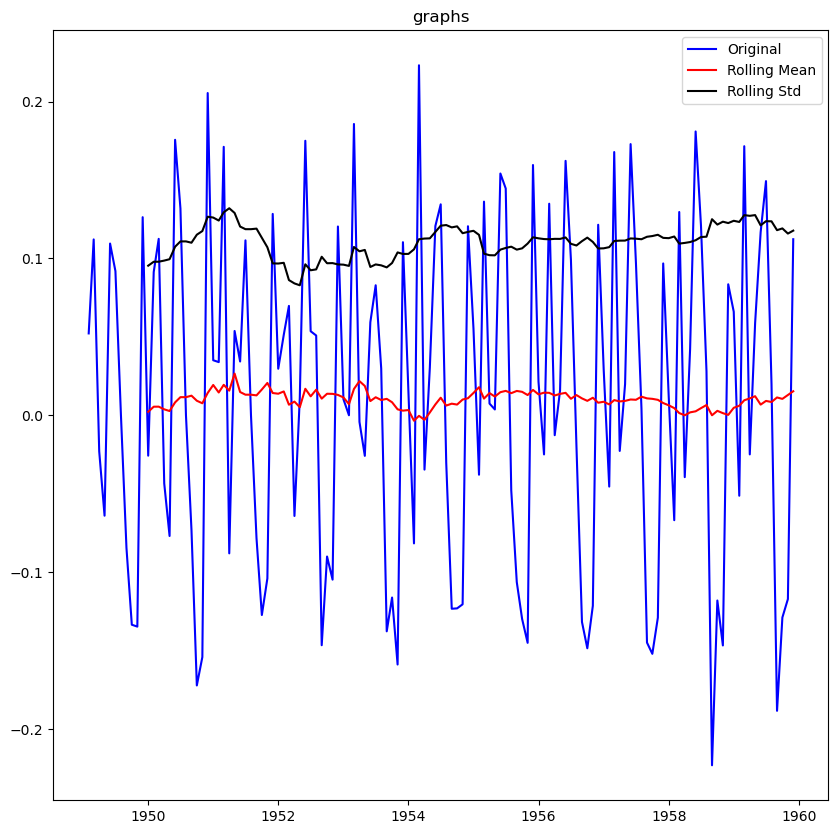

P value 0.029277196976603824
critical values {'1%': -3.487517288664615, '5%': -2.8865777180380032, '10%': -2.5801239192052012}
ADF statistic -3.0647131407731028


In [11]:
ts_logd=ts_log-ts_log.shift()
ts_logd.dropna(inplace=True)
time_stationarity(ts_logd)

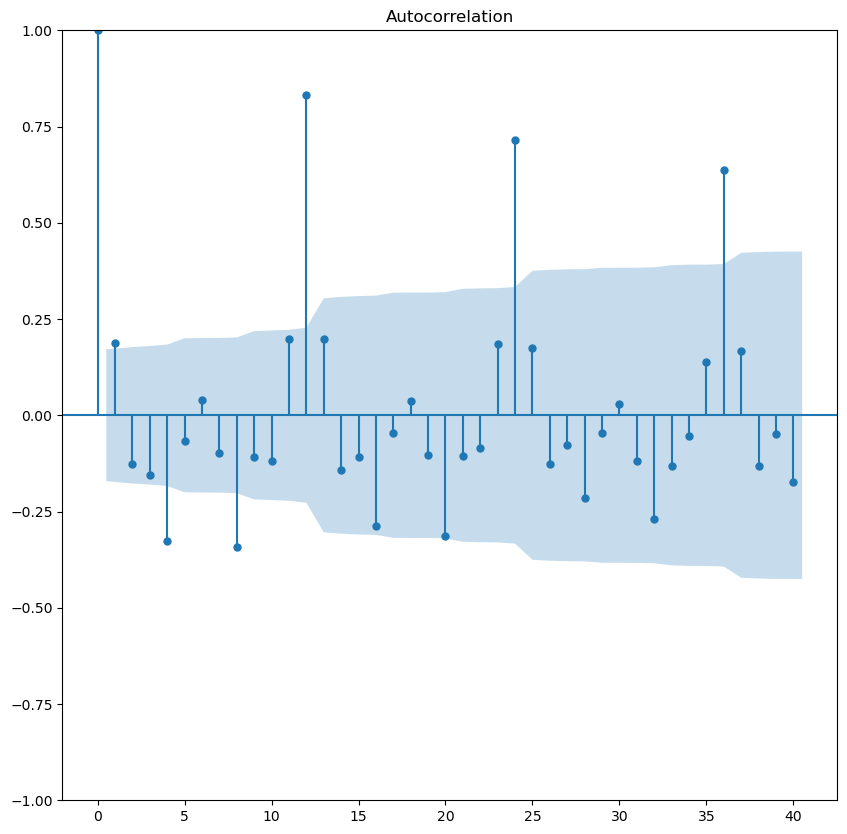

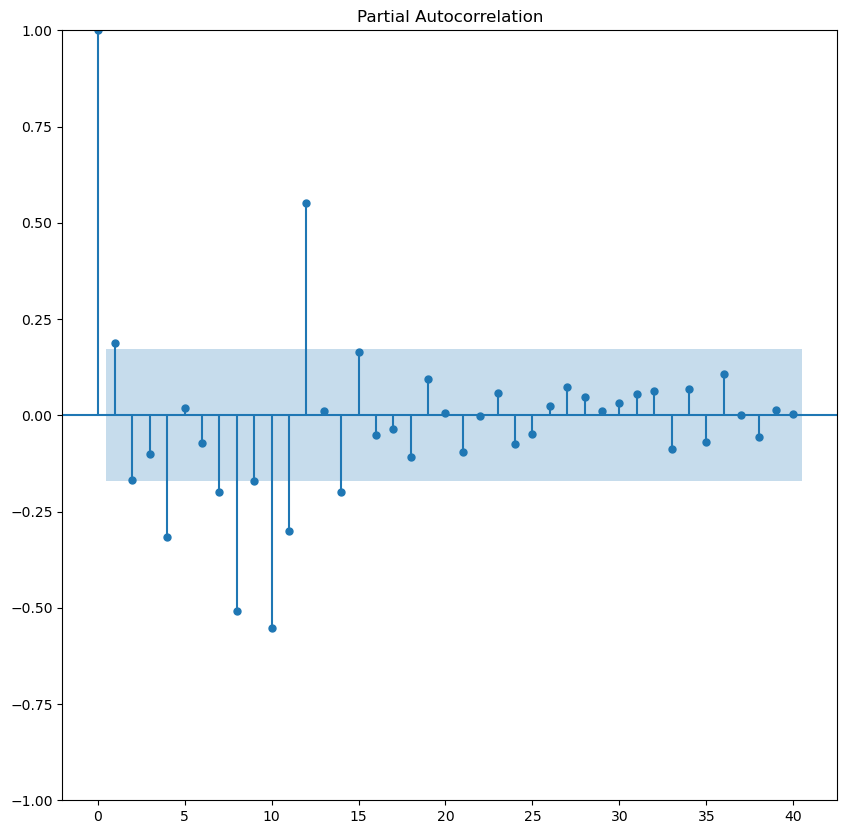

In [12]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

plot_acf(ts_logd, lags=40)
plot_pacf(ts_logd, lags=40, method='ywm')

plt.show()

- from acf graph q=1 and from pacf graph p=1

In [16]:
from statsmodels.tsa.arima.model import ARIMA

p,d,q=1,1,1
model=ARIMA(ts_logd,order=(p,d,q))
model_fit=model.fit()

forecast_logd=model_fit.forecast(steps=len(x_test))

forecast_log=forecast_logd.cumsum()+ts_log[-1]

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\bisha\AppData\Local\Temp\ipykernel_18320\850403887.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  forecast_log=forecast_logd.cumsum()+ts_log[-1]


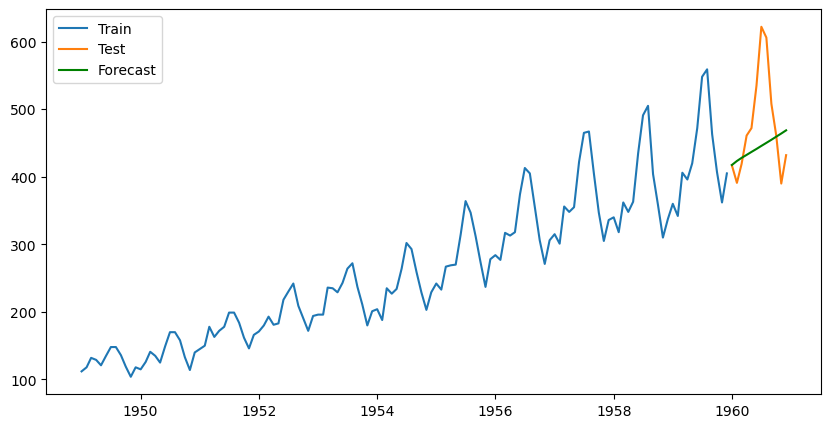

In [17]:
forecast=np.exp(forecast_log)

plt.figure(figsize=(10,5))
plt.plot(x_train.index, x_train, label='Train')
plt.plot(x_test.index, x_test, label='Test')
plt.plot(x_test.index, forecast, label='Forecast', color='green')
plt.legend()
plt.show()

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mean_absolute_error(x_test,forecast)
mean_squared_error(x_test,forecast)

6417.198545176417